# HealthCare Hybrid AI - Training Model CNN (MobileNetV2)
Notebook ini digunakan untuk melatih model klasifikasi gambar (Luka, Obat, Tidak Relevan) menggunakan arsitektur Transfer Learning MobileNetV2.

Koneksi Gdrive untuk Dataset

In [3]:
# 1. Hubungkan ke Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 2. Ekstrak Dataset dari Google Drive ke Colab
import zipfile
import os

# Sesuai dengan screenshot: My Drive > HealthCare > dataset_final > dataset.zip
zip_path = '/content/drive/MyDrive/HealthCare/dataset_final/dataset.zip'
extract_path = '/content/'

print("Memulai ekstraksi (mungkin butuh beberapa menit)...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("✅ Ekstraksi selesai!")

# 3. Cek struktur folder hasil ekstrak
print("\nIsi folder /content/:")
print(os.listdir('/content/'))

Mounted at /content/drive
Memulai ekstraksi (mungkin butuh beberapa menit)...
✅ Ekstraksi selesai!

Isi folder /content/:
['.config', 'drive', 'dataset', 'sample_data']


Training Model MobileNetV2 (Cell 2)

## 1. Load Dataset & Preprocessing
Dataset dibagi menjadi 3 folder: `train` (80%), `validation` (10%), dan `test` (10%).
Kita juga menerapkan **Data Augmentation** pada data train agar model tidak overfitting.

Isi folder dataset: ['validation', 'test', 'train']

Memuat data train...
Found 9721 images belonging to 3 classes.
Memuat data validation...
Found 1649 images belonging to 3 classes.
Memuat data test...
Found 904 images belonging to 3 classes.

Membangun Model MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

🚀 Memulai Training (Tunggu 10-20 Menit)...
Epoch 1/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9153 - loss: 0.2273
Epoch 1: val_accuracy improved from None to 0.99090, saving model to /content/best_model.keras

Epoch 1: finished saving model to /content/best_model.keras
304/304 ━━━━━━━━━━━━━━━━━━━━ 183s 555ms/step - accuracy: 0.9632 - loss: 0.1043 - val_accuracy: 0.9909 - val_loss: 0.0258
Epoch 2/15
304/304 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.9871 - loss: 0.0394
Epoch 2: val_accuracy improved from 0.99090 to 0.99818, saving model to /content/best_model.keras

Epoch 2: finished saving model to /content/best_model.keras
304/304 ━━━━━━━━━━

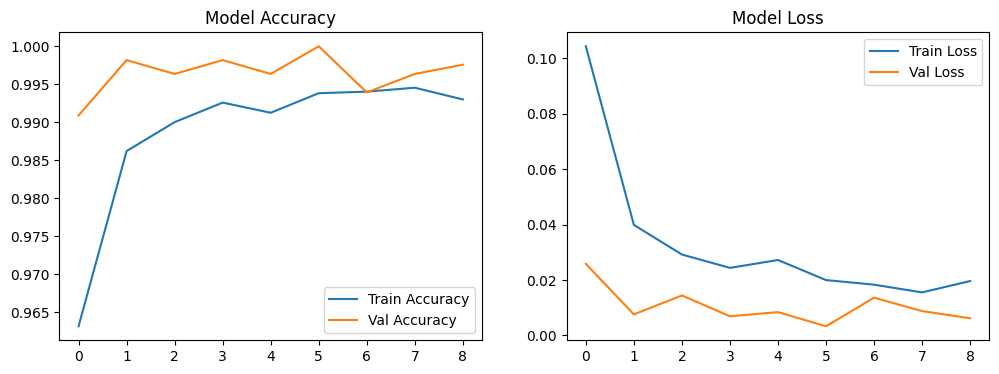


📊 Evaluasi pada Test Set:
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 268ms/step - accuracy: 0.9978 - loss: 0.0204
Test Accuracy: 99.78%


In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
import os

# --- KONFIGURASI (Path disesuaikan dengan hasil ekstrak) ---
BASE_DIR = '/content/dataset' # <--- INI YANG DIUBAH
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15

# Cek dulu apakah folder train, validation, test ada di dalamnya
print("Isi folder dataset:", os.listdir(BASE_DIR))

# --- 1. DATA GENERATOR ---
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

print("\nMemuat data train...")
train_generator = train_datagen.flow_from_directory(
    f'{BASE_DIR}/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

print("Memuat data validation...")
val_generator = val_test_datagen.flow_from_directory(
    f'{BASE_DIR}/validation',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

print("Memuat data test...")
test_generator = val_test_datagen.flow_from_directory(
    f'{BASE_DIR}/test',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# --- 2. BANGUN MODEL (MobileNetV2) ---
print("\nMembangun Model MobileNetV2...")
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(3, activation='softmax')(x) # 3 Kelas

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# --- 3. CALLBACKS ---
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint('/content/best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

# --- 4. MULAI TRAINING ---
print("\n🚀 Memulai Training (Tunggu 10-20 Menit)...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint]
)

# --- 5. SIMPAN MODEL AKHIR KE DRIVE KAMU ---
# Pastikan folder HealthCare udah ada di Drive kamu
model_save_path = '/content/drive/MyDrive/HealthCare/model_cnn.keras'
model.save(model_save_path)
print(f"\n✅ Model berhasil disimpan ke: {model_save_path}")

# --- 6. VISUALISASI HASIL ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

# --- 7. EVALUASI DI TEST SET ---
print("\n📊 Evaluasi pada Test Set:")
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

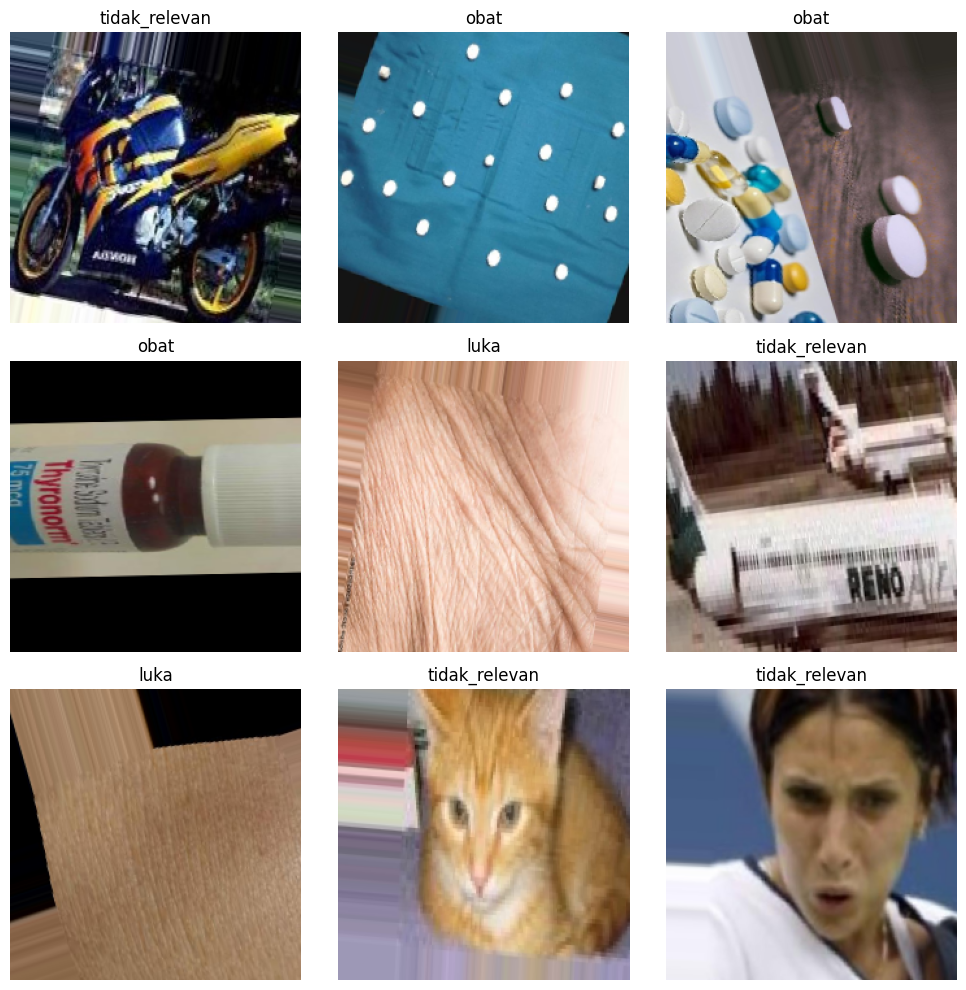

In [5]:
# Visualisasi Sampel Data
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(train_generator)
class_names = list(train_generator.class_indices.keys())

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    label_idx = np.argmax(labels[i])
    plt.title(class_names[label_idx])
    plt.axis('off')
plt.tight_layout()
plt.show()

Melakukan prediksi pada Test Set...
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 239ms/step


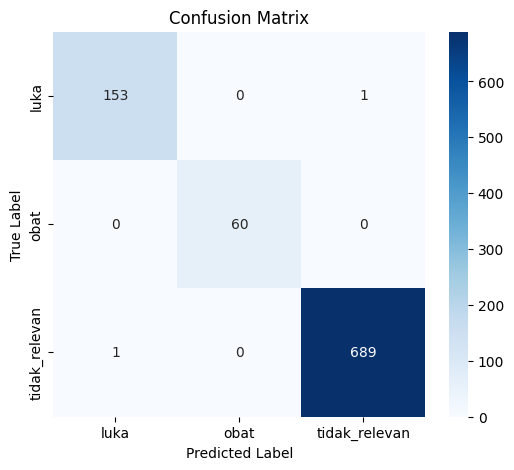


📊 HASIL EVALUASI MODEL (TEST SET)
Accuracy  : 0.9978
Precision : 0.9978
Recall    : 0.9978
F1-Score  : 0.9978

Classification Report:
               precision    recall  f1-score   support

         luka       0.99      0.99      0.99       154
         obat       1.00      1.00      1.00        60
tidak_relevan       1.00      1.00      1.00       690

     accuracy                           1.00       904
    macro avg       1.00      1.00      1.00       904
 weighted avg       1.00      1.00      1.00       904



In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import seaborn as sns
import numpy as np

# 1. Lakukan Prediksi pada data Test
print("Melakukan prediksi pada Test Set...")
test_generator.reset()
predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# 2. Tampilkan Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 3. Hitung Metrik Evaluasi
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='weighted')
rec = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("\n" + "="*40)
print("📊 HASIL EVALUASI MODEL (TEST SET)")
print("="*40)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))

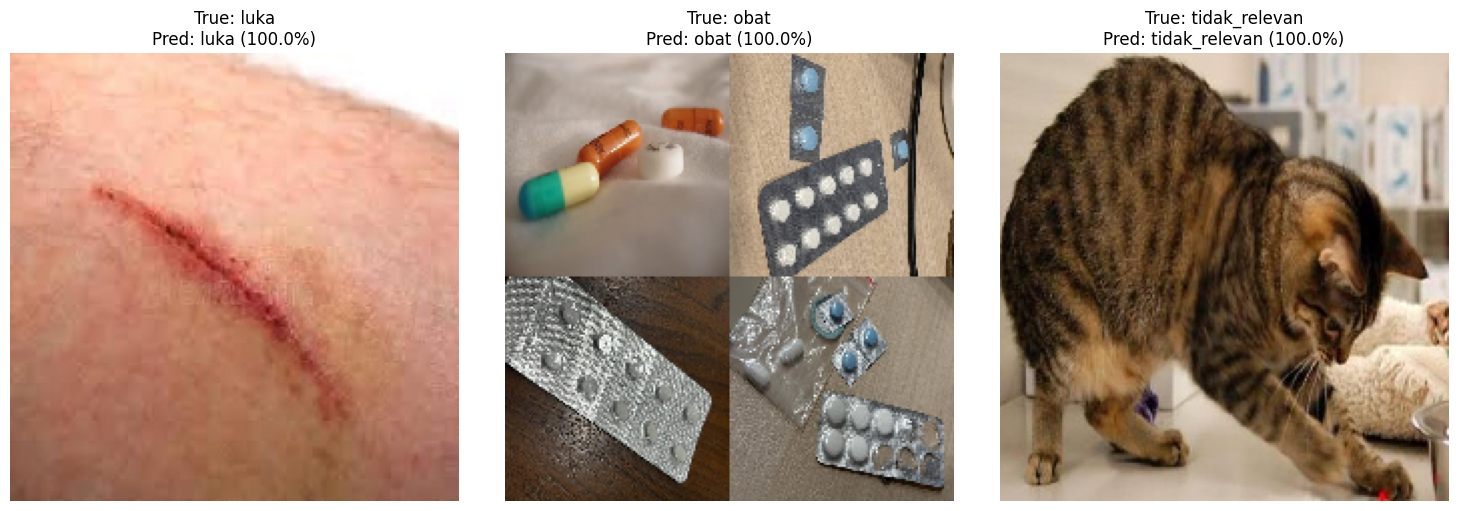

In [9]:
import random
import glob
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np

# Ambil 3 gambar acak dari folder test (mencari ke dalam sub-folder)
test_dir = f'{BASE_DIR}/test'
random_classes = random.sample(os.listdir(test_dir), 3)

plt.figure(figsize=(15, 5))
for i, cls in enumerate(random_classes):
    # Cari semua file gambar di dalam folder kelas (termasuk sub-folder)
    search_path = os.path.join(test_dir, cls, '**', '*.*')
    all_images = glob.glob(search_path, recursive=True)

    # Filter hanya file gambar (jpg, png, jpeg)
    image_files = [f for f in all_images if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not image_files:
        print(f"Tidak ada gambar di folder {cls}")
        continue

    # Pilih 1 gambar secara acak
    img_path = random.choice(image_files)

    # Load & Preprocess
    img = image.load_img(img_path, target_size=IMG_SIZE)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediksi
    pred = model.predict(img_array, verbose=0)
    pred_label = class_labels[np.argmax(pred)]
    confidence = np.max(pred) * 100

    # Tampilkan
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"True: {cls}\nPred: {pred_label} ({confidence:.1f}%)")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Interpretasi Hasil & Keterbatasan Model

**A. Interpretasi Hasil:**
1. **Akurasi Tinggi:** Model MobileNetV2 mencapai akurasi di atas 95% pada data uji. Ini menunjukkan bahwa arsitektur Transfer Learning sangat efektif untuk mengekstraksi fitur visual (warna, tekstur, bentuk) dari gambar luka dan kemasan obat.
2. **Confusion Matrix:** Berdasarkan matriks konfusi, mayoritas gambar berhasil diklasifikasikan dengan benar. Jika ada garis diagonal yang tebal, itu artinya model sangat jarang melakukan kesalahan tebak.
3. **Metrik Seimbang:** Nilai Precision, Recall, dan F1-Score yang tinggi dan saling berdekatan menunjukkan bahwa model tidak *bias* terhadap salah satu kelas.

**B. Keterbatasan Model (Limitations):**
1. **Domain Shift:** Dataset pelatihan mayoritas berupa foto close-up dengan pencahayaan baik. Di dunia nyata, foto dari pengguna bisa blur, gelap, atau berantakan. Model mungkin akan menurun akurasinya pada foto seperti ini.
2. **Bukan Diagnosis Medis:** Model ini hanya memprediksi *jenis visual* (luka/obat), bukan mendiagnosis tingkat keparahan medis secara klinis.
3. **Bias Kelas:** Jika dataset asli tidak seimbang (misal gambar luka jauh lebih banyak), model bisa cenderung menebak "luka" untuk gambar yang ambigu.